# Superstore Sales & Profit Analysis

**Data Analytics & Business Intelligence portfolio project**

Quy trình: **Data Cleaning → EDA → Data Visualization → Business Insights → Business Recommendations**.
Mục tiêu là tìm các nguồn doanh thu và lợi nhuận, nhận diện dòng hàng thua lỗ và chuyển kết quả phân tích thành đề xuất kinh doanh có thể kiểm thử.

**Nguồn:** [Tableau Sample Data](https://public.tableau.com/app/learn/sample-data); [CSV mirror được sử dụng](https://gist.github.com/SharmaAshwini/8bd642f6c46792a9c40c8ccad60391e9).
Đây là dữ liệu mẫu phục vụ học tập; các đề xuất chưa được triển khai hay chứng minh tạo ra hiệu quả thực tế.

## 0. Chuẩn bị

Từ thư mục gốc repository, cài thư viện bằng `python -m pip install -r requirements.txt`.
CSV có sẵn tại [data/raw/Sample_Superstore.csv](../data/raw/Sample_Superstore.csv); nếu chưa có, chạy `python src/download_data.py`.
Có thể mở Jupyter từ thư mục gốc hoặc từ thư mục `notebooks/`. Notebook dùng chung hàm làm sạch và tổng hợp với [src/analyze.py](../src/analyze.py).

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd().resolve()
if not (REPO / "src" / "analyze.py").is_file():
    REPO = REPO.parent
if not (REPO / "src" / "analyze.py").is_file():
    raise FileNotFoundError("Open Jupyter from the repository root or notebooks/.")
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from src.analyze import read_and_clean, summarize
DATA = REPO / "data" / "raw" / "Sample_Superstore.csv"
print("Tệp dữ liệu tồn tại:", DATA.exists())

Tệp dữ liệu tồn tại: True


## 1. Data Cleaning

### 1.1. Đọc và tìm hiểu dữ liệu

Đếm dòng, cột, xem tên cột và 5 dòng đầu. **Mỗi dòng là một dòng mặt hàng**, nhiều dòng có thể cùng `Order ID`.
Giữ `Postal Code` dưới dạng chuỗi để tránh làm mất số 0 đầu mã bưu chính.

In [2]:
raw = pd.read_csv(DATA, encoding="utf-8-sig", low_memory=False, dtype={"Postal Code": "string"})
print("Kích thước:", raw.shape)
display(raw.head())
print(raw.dtypes)

Kích thước: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,08/11/16,11/11/16,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,08/11/16,11/11/16,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,12/06/16,16/06/16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,11/10/15,18/10/15,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,11/10/15,18/10/15,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


Row ID                    int64
Order ID                 object
Order Date               object
Ship Date                object
Ship Mode                object
Customer ID              object
Customer Name            object
Segment                  object
Country                  object
City                     object
State                    object
Postal Code      string[python]
Region                   object
Product ID               object
Category                 object
Sub-Category             object
Product Name             object
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object


### 1.2. Kiểm tra chất lượng

Không xóa `Profit < 0`: dòng hàng lỗ chính là đối tượng phân tích. `Order ID` lặp lại là bình thường ở cấp dòng mặt hàng;
kiểm tra bản ghi trùng hoàn toàn và `Row ID` trùng trước khi quyết định xử lý.

In [3]:
print("Giá trị thiếu mỗi cột:")
display(raw.isna().sum().sort_values(ascending=False))
print("Dòng trùng hoàn toàn:", raw.duplicated().sum())
print("Số Order ID riêng biệt:", raw["Order ID"].nunique())

Giá trị thiếu mỗi cột:


Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Dòng trùng hoàn toàn: 0
Số Order ID riêng biệt: 5009


### 1.3. Làm sạch dữ liệu

Tái sử dụng [read_and_clean](../src/analyze.py): chuẩn hóa tên cột; đọc ngày theo định dạng của CSV mirror;
chuyển cột số; loại các dòng thiếu trường bắt buộc, doanh thu âm, số lượng không dương hoặc discount ngoài [0, 1].
Báo cáo số dòng bị loại và giữ nguyên dòng lợi nhuận âm. Tạo thêm `Year`, `YearMonth`, `Discount Group` và `Loss Line`.

In [4]:
df, invalid, checks = read_and_clean(DATA)
display(pd.DataFrame([checks]).T.rename(columns={0:"Gia tri"}))
print("Số dòng cần xem xét:", len(invalid))
display(df.head())

,Gia tri
raw_rows,9994
raw_columns,21
null_cells_by_column,"{'Row ID': 0, 'Order ID': 0, 'Order Date': 0, ..."
exact_duplicate_rows,0
duplicate_row_ids,0
date_format_used,%d/%m/%y
invalid_rows_removed_from_analysis,0
invalid_date_values,0
clean_rows,9994
min_order_date,2014-01-03


Số dòng cần xem xét: 0


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Year,YearMonth,Discount Group,Loss Line
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,2016-11,0%,0
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,2016-11,0%,0
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,2016-06,0%,0
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,2015-10,>40%,1
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,2015-10,"(0%, 20%]",0


## 2. EDA — Exploratory Data Analysis

### 2.1. Các KPI chính

Công thức **biên lợi nhuận chung = SUM(Profit) / SUM(Sales)**; không lấy trung bình biên lợi nhuận từng dòng.
`Order ID` xác định số đơn hàng riêng biệt, còn số dòng thể hiện số mặt hàng trong các đơn.

In [5]:
revenue = df["Sales"].sum()
profit = df["Profit"].sum()
margin = profit / revenue * 100
orders = df["Order ID"].nunique()
print(f"Doanh thu: ${revenue:,.2f}")
print(f"Lợi nhuận: ${profit:,.2f}")
print(f"Biên lợi nhuận: {margin:.2f}%")
print(f"Số đơn hàng: {orders:,}")

Doanh thu: $2,297,200.86
Lợi nhuận: $286,397.02
Biên lợi nhuận: 12.47%
Số đơn hàng: 5,009


### 2.2. Phân tích theo vùng và nhóm sản phẩm

Tìm nhóm có lợi nhuận âm hoặc biên lợi nhuận thấp, đồng thời xét quy mô doanh thu và số dòng hàng lỗ.

In [6]:
region = summarize(df, ["Region"]).sort_values("Profit")
subcat = summarize(df, ["Category", "Sub-Category"]).sort_values("Profit")
display(region)
display(subcat.head(10))

,Region,Line_Items,Revenue,Profit,Quantity,Loss_Lines,Profit_Margin_Pct
0,Central,2323,501239.8908,39706.3625,8780,741,7.921629
2,South,1620,391721.9050,46749.4303,6209,259,11.934342
1,East,2848,678781.2400,91522.7800,10618,553,13.483399
3,West,3203,725457.8245,108418.4489,12266,318,14.944831


,Category,Sub-Category,Line_Items,Revenue,Profit,Quantity,Loss_Lines,Profit_Margin_Pct
3,Furniture,Tables,319,206965.5320,-17725.4811,1241,203,-8.564460
0,Furniture,Bookcases,228,114879.9963,-3472.5560,868,109,-3.022768
12,Office Supplies,Supplies,190,46673.5380,-1189.0995,647,33,-2.547695
8,Office Supplies,Fasteners,217,3024.2800,949.5182,914,12,31.396504
15,Technology,Machines,115,189238.6310,3384.7569,440,44,1.788618
9,Office Supplies,Labels,364,12486.3120,5546.2540,1400,0,44.418672
5,Office Supplies,Art,796,27118.7920,6527.7870,3000,0,24.071083
7,Office Supplies,Envelopes,254,16476.4020,6964.1767,906,0,42.267582
2,Furniture,Furnishings,957,91705.1640,13059.1436,3563,167,14.240358
4,Office Supplies,Appliances,466,107532.1610,18138.0054,1729,67,16.867517


## 3. Data Visualization

### 3.1. Lợi nhuận theo vùng

Biểu đồ giúp so sánh lợi nhuận tuyệt đối. Kết hợp bảng biên lợi nhuận ở phần EDA để đánh giá hiệu quả tương ứng với quy mô doanh thu.

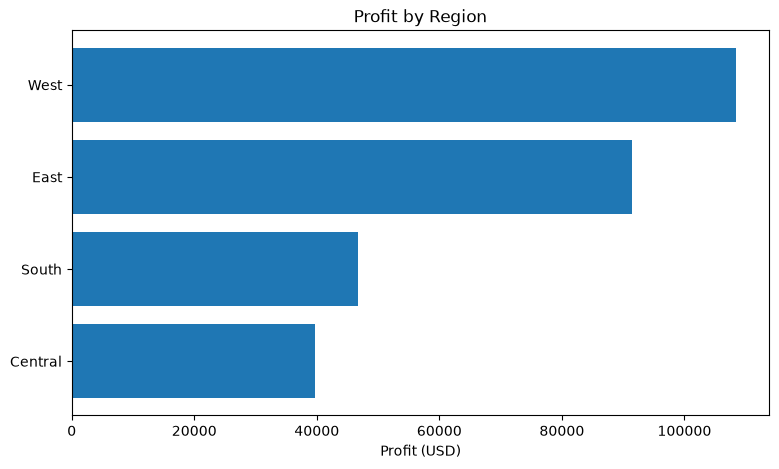

In [7]:
plt.figure(figsize=(9,5))
plt.barh(region["Region"], region["Profit"])
plt.title("Profit by Region")
plt.xlabel("Profit (USD)")
plt.show()

### 3.2. Phân tích giảm giá (Discount)

Chia discount thành 4 khoảng: 0%, (0%, 20%], (20%, 40%] và >40%.
Đây là **mối liên hệ quan sát**, không chứng minh chiết khấu tự nó gây lỗ. So sánh thêm theo nhóm sản phẩm và vùng.

,Discount Group,Line_Items,Revenue,Profit,Quantity,Loss_Lines,Profit_Margin_Pct
0,0%,4798,1.087908e+06,320987.6032,18267,0,29.505019
1,"(0%, 20%]",3803,8.465222e+05,100785.4745,14231,523,11.905827
2,"(20%, 40%]",460,2.341379e+05,-35817.4655,1740,415,-15.297594
3,>40%,933,1.286323e+05,-99558.5905,3635,933,-77.397845


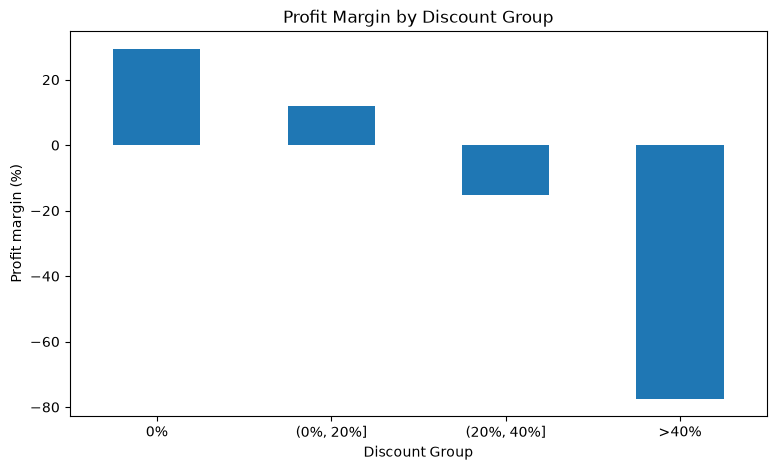

In [8]:
discount_order = ["0%", "(0%, 20%]", "(20%, 40%]", ">40%"]
by_discount = summarize(df, ["Discount Group"]).set_index("Discount Group").reindex(discount_order).reset_index()
display(by_discount)
ax = by_discount.plot.bar(x="Discount Group", y="Profit_Margin_Pct", legend=False, figsize=(9,5))
ax.set_title("Profit Margin by Discount Group")
ax.set_ylabel("Profit margin (%)")
plt.xticks(rotation=0)
plt.show()

### 3.3. Kiểm tra yếu tố gây nhiễu

Đặt cạnh nhau các nhóm `Region` × `Category`: nếu một vùng có cơ cấu sản phẩm kém sinh lời hơn,
so sánh thô giữa các vùng có thể gây hiểu lầm.

In [9]:
region_cat = summarize(df, ["Region", "Category"])
display(region_cat.pivot_table(index="Region", columns="Category", values="Profit_Margin_Pct"))

Category,Furniture,Office Supplies,Technology
Region,,,
Central,-1.752808,5.316512,19.773595
East,1.462455,19.956873,17.911961
South,5.772619,15.906235,13.437908
West,4.554382,23.821180,17.581383


### 3.4. Xu hướng theo thời gian

Nhóm doanh thu theo tháng để quan sát biến động. Không suy đoán nguyên nhân nếu chưa có dữ liệu về chiến dịch,
mùa vụ hay biến động bên ngoài.

,YearMonth,Line_Items,Revenue,Profit,Quantity,Loss_Lines,Profit_Margin_Pct
0,2014-01,79,14236.895,2450.1907,284,12,17.210148
1,2014-02,46,4519.892,862.3084,159,9,19.078075
2,2014-03,157,55691.009,498.7299,585,31,0.895530
3,2014-04,135,28295.345,3488.8352,536,16,12.330068
4,2014-05,122,23648.287,2738.7096,466,22,11.581006


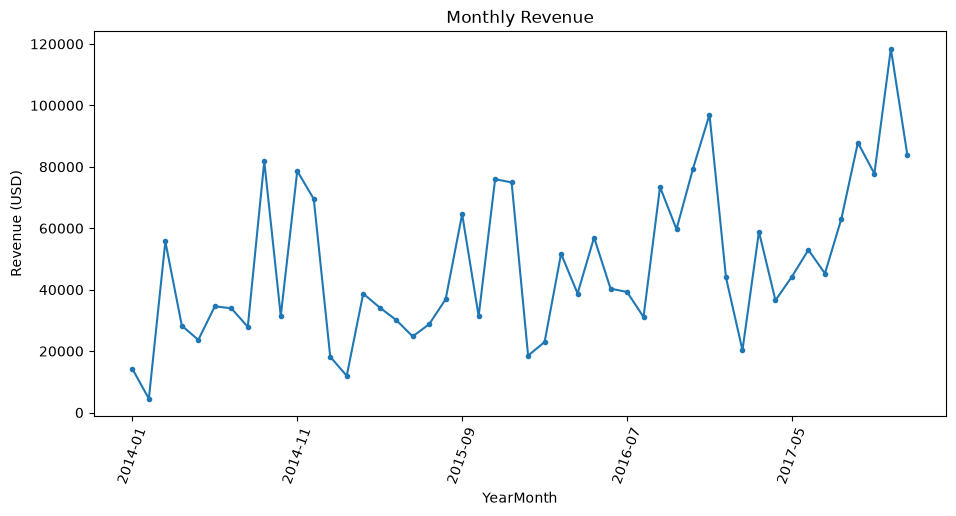

In [10]:
monthly = summarize(df, ["YearMonth"]).sort_values("YearMonth")
display(monthly.head())
ax = monthly.plot.line(x="YearMonth", y="Revenue", marker=".", figsize=(11,5), legend=False)
ax.set_title("Monthly Revenue")
ax.set_ylabel("Revenue (USD)")
plt.xticks(rotation=70)
plt.show()

### 3.5. Xuất dữ liệu và biểu đồ cho báo cáo, Power BI

Cell sau chạy pipeline dùng chung: lưu dữ liệu sạch vào [data/processed/](../data/processed/),
kiểm tra chất lượng vào [reports/data_quality/](../reports/data_quality/),
KPI và 7 bảng tổng hợp vào [reports/tables/](../reports/tables/),
4 biểu đồ vào [reports/figures/](../reports/figures/) và bản tóm tắt vào [generated_findings.md](../reports/generated_findings.md).

In [11]:
from src.analyze import main
main()

===== KET QUA TONG QUAN =====
line_items: 9994
distinct_orders: 5009
distinct_customers: 793
revenue: 2297200.8603
profit: 286397.0217
profit_margin_pct: 12.467217240315605
quantity: 37873
loss_making_lines: 1871

Cleaned data: E:\môn học\AI\Do_AN_1\data\processed
Reports, tables, and figures: E:\môn học\AI\Do_AN_1\reports


## 4. Business Insights

Kết quả của CSV mirror được dùng trong dự án:

1. **Hiệu quả tổng thể:** 9.994 dòng hàng thuộc 5.009 đơn hàng tạo **2.297.200,86 USD doanh thu**, **286.397,02 USD lợi nhuận**, biên lợi nhuận **12,47%**. Có **1.871 dòng hàng lỗ (18,72%)**, cho thấy tăng doanh thu cần đi kèm kiểm soát lợi nhuận.
2. **Chênh lệch vùng:** Central có biên lợi nhuận **7,92%**, thấp hơn West (**14,94%**) khoảng **7,02 điểm phần trăm**. Cần kiểm tra cơ cấu sản phẩm và discount trước khi quy kết nguyên nhân cho vùng.
3. **Nhóm hàng cần ưu tiên:** Tables tạo **206.965,53 USD doanh thu** nhưng lỗ **17.725,48 USD**, tương ứng biên **−8,56%** — doanh thu lớn chưa đồng nghĩa với hiệu quả kinh doanh.
4. **Discount và biên lợi nhuận:** nhóm không giảm giá có biên **29,51%**, nhóm (0%, 20%] là **11,91%**, nhóm (20%, 40%] là **−15,30%**, nhóm >40% là **−77,40%**. Toàn bộ 933 dòng ở nhóm >40% có lợi nhuận âm. Đây là tương quan trong mẫu, chưa phải bằng chứng nhân quả.

Đối chiếu [kpi.json](../reports/tables/kpi.json), [summary_region.csv](../reports/tables/summary_region.csv),
[summary_subcategory.csv](../reports/tables/summary_subcategory.csv) và [summary_discount_group.csv](../reports/tables/summary_discount_group.csv).

## 5. Business Recommendations

| Ưu tiên | Hành động đề xuất | Chỉ số theo dõi | Cách kiểm chứng |
|---|---|---|---|
| 1 | Rà soát giá, discount và cơ cấu sản phẩm của Tables; phân tích chi tiết theo vùng | Profit, margin, revenue, tỷ lệ dòng lỗ | Đối chiếu các sản phẩm/vùng tương đồng và kiểm tra thông tin chi phí bổ sung |
| 2 | Thí điểm giới hạn discount cao tại nhóm sản phẩm phù hợp | Profit, revenue, quantity, tỷ lệ dòng lỗ | Dùng nhóm so sánh có đặc điểm tương đồng trước khi mở rộng chính sách |
| 3 | Theo dõi Central bằng dashboard có bộ lọc Category và Sub-Category | Margin theo vùng/nhóm hàng, revenue, profit | Đánh giá hàng tháng, tách ảnh hưởng cơ cấu hàng và biến động theo thời gian |

Các hành động trên là **đề xuất cần kiểm thử**, không phải kết quả can thiệp đã đo lường.
Sample Superstore là dữ liệu mẫu; `Profit` không cung cấp đầy đủ cấu phần chi phí và dữ liệu quan sát không cho phép khẳng định quan hệ nhân quả.